# 04 · Classifier

**Goal:** replace notebook 03's hand-set rules with models that learn from the data, and compare them with the rules and CMID only on the same scorecard.

The classifier works in two steps, the standard setup for record matching:
1. **Score every pair.** For each (entry, candidate matter) row, a model gives the probability that it's the right matter.
2. **Decide the action.** A second model looks at the whole entry and gives the probability that the top pick is safe to accept, that the entry covers two matters, or that it's a new client or matter. Cutoffs tuned on TRAIN turn those into one of the five decisions.

Every decision also gets a short and a full reason, built from that entry's own clues.

**What counts as good:** the decisions made with no person (`AUTO_MATCH` and `NO_MATCH`) are almost always right, and as many entries as possible are decided that way (the **straight-through rate**). Three settings are kept:

| Setting | Target |
|---|---|
| Strict | at least 98% of decisions made with no person are right |
| **Default** (chosen) | at least 97% |
| Balanced | the rules' accuracy, to show how much more can be automated at the same accuracy |

**Questions**
1. Which model ranks the right matter first most often: logistic regression or gradient boosting?
2. Can its probabilities be trusted as confidence scores?
3. How far does one step (cutoffs on the top probabilities) get, and what holds it back?
4. Does the second step reach the targets, and at what straight-through rate?
5. Which clues matter most?
6. Do the results hold on VAL?
7. What does a reviewer see for each decision?

## 1. Setup

In [1]:
import itertools
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import fbeta_score, log_loss
from sklearn.model_selection import GridSearchCV, PredefinedSplit, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier

sys.path.insert(0, "../src")
from rules import (ACTIONS, OUTCOMES, answer_key, pick_best, pick_robust, precision_ci, run_rules, score, cmid_only,
                   summarize, cutoff_stability)
from classifier import (top_candidates, route, top_k_accuracy, entry_features, action_labels, route_actions,
                        multi_text_model, explain, ACTION_FEATURES)
from train import SETTINGS, fit_pair_model, fit_action_model, pick_cutoffs

In [2]:
RESULTS_DIR = Path("../results")
SEED = 210

LR_GRID = {"logisticregression__C": [0.01, 0.1, 1, 10]}
GB_GRID = {"num_leaves": [15, 31], "min_child_samples": [20, 100, 200], "n_estimators": [100, 200, 400]}
ROUTE_GRID = {
    "auto_min": [0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 0.995, 0.999],
    "multi_min": [0.5, 0.7, 0.9],
    "no_match_max": [0.02, 0.05, 0.1, 0.2],
}
ACTION_GRID = {
    "auto_min": [0.5, 0.7, 0.8, 0.85, 0.9, 0.93, 0.95, 0.97, 0.98, 0.99, 0.995],
    "no_match_min": [0.3, 0.5, 0.7, 0.9, 0.95],
}
MULTI_GRID = np.round(np.arange(0.05, 0.95, 0.05), 2)
MULTI_BETA = 2   # a missed multi-matter entry counts about twice as much as a false alarm (section 7)
ACTION_GB_GRID = {"n_estimators": [50, 100, 200], "num_leaves": [4, 7, 31], "min_child_samples": [20, 50, 100]}
TEXT_GRID = {"logisticregression__C": [0.3, 1, 3, 10]}
DEFAULT_TARGET = 0.97   # the chosen setting: at least 97% of automatic decisions right (section 7)
CORRECT_TYPED_CMID = True   # auto-match to the top pick when it's confident a typed CMID is wrong (False = flag it)
STABILITY_RESAMPLES = 200   # TRAIN resamples for the cutoff stability check (section 7)
ROBUST_SHARE = 0.9   # a setting has to reach its target in at least 90% of those resamples (section 7)

## 2. Load data

- **Pairs table** from notebook 02: 103 rows per entry, one per candidate matter. `is_true_matter` is the label (1 for the right matter, and for both matters of a multi-matter entry).
- **`fold`** puts each TRAIN entry in one of notebook 02's 5 cross-validation folds.
- **Parts table:** one row per piece of work, only used to suggest how to divide multi-matter entries.

The answer key (`key_` columns) is only used for labels and scoring.

In [3]:
pairs = pd.read_parquet(RESULTS_DIR / "02_pairs.parquet")
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
rules_config = json.loads((RESULTS_DIR / "03_config.json").read_text())
baseline = pd.read_csv(RESULTS_DIR / "03_comparison.csv")
answers = answer_key(pairs)
parts = pd.read_parquet(RESULTS_DIR / "02_parts.parquet")
narratives = pairs.drop_duplicates("entry_id").set_index("entry_id")["narrative_norm"]

feature_groups = feature_config["features"]
FEATURES = [col for cols in feature_groups.values() for col in cols]
CLIENT_COL, MATTER_COL = feature_config["client_col"], feature_config["matter_col"]
PRECISION_TARGET = rules_config["precision_target"]

train_pairs = pairs[pairs["split"] == "TRAIN"].reset_index(drop=True)
val_pairs = pairs[pairs["split"] == "VAL"].reset_index(drop=True)
X_train, y_train = train_pairs[FEATURES], train_pairs["is_true_matter"]
cv = PredefinedSplit(train_pairs["fold"])

assert (pairs.groupby("entry_id").size() == pairs["cmid"].nunique()).all()
assert pairs[FEATURES].notna().all().all()
assert train_pairs.groupby("entry_id")["fold"].nunique().eq(1).all()
print(f"{len(FEATURES)} features | TRAIN: {train_pairs['entry_id'].nunique():,} entries ({len(train_pairs):,} pairs) | "
      f"VAL: {val_pairs['entry_id'].nunique():,} entries | right matter in {y_train.mean():.1%} of TRAIN pairs")

48 features | TRAIN: 2,802 entries (288,606 pairs) | VAL: 601 entries | right matter in 1.0% of TRAIN pairs


- **Row accuracy is useless here.** About 1 in 100 pairs is the right matter, so a model that always says "no" would be 99% accurate. Everything below is measured per entry instead.

## 3. How the classifier decides

### Step 1: score every pair

| Model | Why it's here |
|---|---|
| Logistic regression | one weight per clue, easy to read, a good sanity check |
| Gradient boosting (LightGBM) | many small decision trees, each fixing the last one's mistakes. It can learn combinations ("typed client matches *and* the timekeeper billed it") that one weight per clue can't. It's the usual choice for tables of features like this one. |

**Keeping entries together.** All 103 rows of an entry have to land in the same fold. Otherwise the model sees part of an entry while training and gets graded on the rest. `PredefinedSplit` uses notebook 02's folds, the same ones the past-narrative clue was built with.

### Step 2: decide the action

First a one-step version for comparison (`route` in `src/classifier.py`), with cutoffs on the top two probabilities:

| # | If... | Then |
|---|---|---|
| 1 | no candidate scores above `no_match_max` | `NO_MATCH` |
| 2 | the second-best candidate scores at least `multi_min` | `MULTI_MATTER` |
| 3 | a valid typed CMID isn't the top pick, or the typed matter wasn't open | `FLAG_MISMATCH` |
| 4 | the top pick scores at least `auto_min` but wasn't open | `FLAG_MISMATCH` |
| 5 | the top pick scores at least `auto_min` | `AUTO_MATCH` |
| 6 | otherwise | `NEEDS_REVIEW` with a top-3 shortlist |

Then the **action model** (section 7), which replaces cutoffs on raw probabilities with learned probabilities for each action.

### Scoring and picking cutoffs

Same as notebook 03 (`score` and `summarize` in `src/rules.py`): among settings that reach the target, the highest straight-through rate; if none do, the highest precision to the half point. Section 7 adds a margin to this rule.

## 4. Step 1: tune and compare the two models (TRAIN)

Each grid is searched over the 5 folds and scored by **log loss** (how far the probabilities are from the 0/1 labels, lower is better).
- **Number of trees** (`n_estimators`) is tuned in the grid instead of with early stopping. Early stopping holds out a random slice of *rows*, so one entry could land on both sides, the same leak the folds avoid.
- **Learning rate** stays at 0.05.
- **Speed:** logistic regression runs its grid fits in parallel (`n_jobs=-1`), and LightGBM already uses every core inside each fit.

In [4]:
searches = {
    "logistic regression": GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                                        LR_GRID, cv=cv, scoring="neg_log_loss", n_jobs=-1),
    "gradient boosting": GridSearchCV(LGBMClassifier(learning_rate=0.05, random_state=SEED, verbose=-1),
                                      GB_GRID, cv=cv, scoring="neg_log_loss"),
}
for name, search in searches.items():
    search.fit(X_train, y_train)
    print(f"{name}: {search.best_params_} | log loss {-search.best_score_:.4f}")

logistic regression: {'logisticregression__C': 10} | log loss 0.0131
gradient boosting: {'min_child_samples': 200, 'n_estimators': 400, 'num_leaves': 31} | log loss 0.0087


In [5]:
gb_grid = pd.DataFrame(searches["gradient boosting"].cv_results_)
gb_grid["log_loss"] = -gb_grid["mean_test_score"]
gb_grid[["param_num_leaves", "param_min_child_samples", "param_n_estimators", "log_loss", "mean_fit_time"]].sort_values("log_loss").round(4)

,param_num_leaves,param_min_child_samples,param_n_estimators,log_loss,mean_fit_time
17,31,200,400,0.0087,3.6508
16,15,200,400,0.0088,2.0037
15,31,200,200,0.0088,1.8609
9,31,100,200,0.0089,1.8182
11,31,100,400,0.0089,3.4379
10,15,100,400,0.0089,1.9986
14,15,200,200,0.0092,1.1435
8,15,100,200,0.0093,1.1070
7,31,100,100,0.0094,1.0015
5,31,20,400,0.0094,3.4363


- **Gradient boosting's log loss is about a third lower** than logistic regression's (0.0087 vs. 0.0131).
- The best settings are the largest in the grid (400 trees, 31 leaves, at least 200 rows per leaf), but the top four are within 0.0002 of each other, so the exact choice matters little.

### Cross-validated probabilities

Each model is refit fold by fold with its best settings, so every TRAIN entry gets probabilities from a model that never saw it. Everything tuned in sections 6 and 7 uses these.
- **Top-1:** share of entries whose right matter is ranked first
- **Top-3:** share where it's in the top three (what a reviewer's shortlist shows)

In [6]:
cv_probs = {name: cross_val_predict(search.best_estimator_, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
            for name, search in searches.items()}

model_scores = pd.DataFrame({name: {"log_loss": log_loss(y_train, p),
                                    "top_1": top_k_accuracy(train_pairs, p, k=1),
                                    "top_3": top_k_accuracy(train_pairs, p, k=3)}
                             for name, p in cv_probs.items()}).T
chosen_model = model_scores["top_1"].idxmax()
best_model = searches[chosen_model].best_estimator_
print("Chosen model:", chosen_model)
model_scores.round(3)

Chosen model: gradient boosting


,log_loss,top_1,top_3
logistic regression,0.013,0.863,0.958
gradient boosting,0.009,0.924,0.976


- **Gradient boosting ranks the right matter first for 92% of entries**, vs. 86% for logistic regression, and has it in the top 3 for 98%.
- Its log loss is also about a third lower, so the gain isn't just in the ranking: the probabilities themselves are closer to the truth.

## 5. Can the probabilities be trusted?

Cutoffs only make sense if 0.9 really means "right about 9 times in 10". A **calibration plot** checks this: candidates are grouped by predicted probability, and each group's average prediction is plotted against how often it was the right matter. A calibrated model sits on the diagonal.

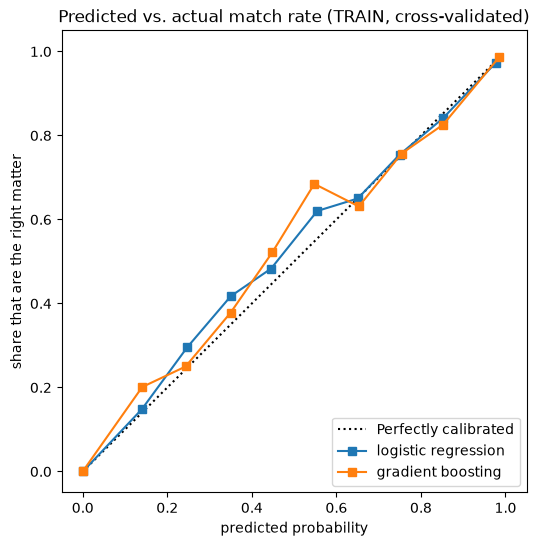

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, p in cv_probs.items():
    CalibrationDisplay.from_predictions(y_train, p, n_bins=10, name=name, ax=ax)
ax.set(title="Predicted vs. actual match rate (TRAIN, cross-validated)", xlabel="predicted probability", ylabel="share that are the right matter")
plt.show()

- **Both models stay close to the diagonal.** Gradient boosting is a little under-confident between 0.4 and 0.6 (right more often than it says), which is the safe direction.
- **So its probabilities can be used as confidence scores** without an extra calibration step. Notebook 05 checks this again on each entry's top pick, the probability a reviewer actually sees.

## 6. One step: cutoffs on the top probabilities (TRAIN)

Every combination of the three cutoffs is tried on the cross-validated probabilities (108 combinations).

In [8]:
ranked_train = top_candidates(train_pairs, cv_probs[chosen_model])

one_sweep = {}
for settings in itertools.product(*ROUTE_GRID.values()):
    one_sweep[settings] = summarize(score(route(ranked_train, dict(zip(ROUTE_GRID, settings))), answers))
one_sweep = pd.DataFrame(one_sweep).T.rename_axis(list(ROUTE_GRID))

one_step = {k: float(v) for k, v in zip(ROUTE_GRID, pick_best(one_sweep, PRECISION_TARGET))}
scored_one = score(route(ranked_train, one_step), answers)
wrong_one = scored_one[scored_one["outcome"] == "Accepted, wrong"]
print("Cutoffs:", one_step)
print({k: round(v, 3) for k, v in summarize(scored_one).items() if k in ["decided_precision", "straight_through", "review_share"]})
wrong_one["key_entry_category"].value_counts().rename("wrong auto-accepts").to_frame()

Cutoffs: {'auto_min': 0.999, 'multi_min': 0.9, 'no_match_max': 0.02}
{'straight_through': 0.16, 'decided_precision': 0.96, 'review_share': 0.744}


,wrong auto-accepts
key_entry_category,
MULTI_UNNAMED,6
MULTI_NAMED,3


- **One step tops out at 96%.** Nothing reaches 97% or 98%, so the rule falls back to the most precise setting, `auto_min` 0.999, which decides only 16% of entries with no person.
- **Every wrong auto-accept left is a multi-matter entry** (9 of 9): the right matter is accepted, but the entry covered two matters. A cutoff on one candidate's probability can't see that, so it's what step 2 is for.

## 7. Step 2: an action model

### Entry-level clues

Each TRAIN entry gets one row of clues (`entry_features` in `src/classifier.py`):
- **Scores:** the top three probabilities, their total, and whether the top two are the same client
- **Typed fields:** how the typed CMID compares with the top pick, and the best typed-name scores
- **Narrative:** number of parts, task types, matters and clients named, and past-narrative scores for the top picks
- **Evidence for another matter** (`n_other_sources`, 0 to 3): another client named, someone named who was billed with another client, another matter named by its own key term. This is how step 2 notices a narrative that's about someone else's matter.

### Labels (`action_labels`)

| Label | When |
|---|---|
| `multi` | the entry covers more than one matter |
| `no_match` | the client or matter isn't in Matter Master |
| `auto` | otherwise, and the top pick is right |
| `review` | otherwise (the top pick is wrong) |

### The model

- **A second LightGBM model** learns these labels from the cross-validated step-1 probabilities, on the same folds, so it never sees a probability from a model that saw the entry.
- **Tuned like step 1:** number of trees, tree size (`num_leaves`), and leaf size, by log loss. Smaller trees are in the grid because there are only about 2,800 TRAIN entries to learn from (notebook 08).
- **No early stopping:** with this few entries, the result depends too much on which ones land in the held-out slice.

### Narrative score

Multi-matter entries are hard to spot from scores alone. Block-billed entries also have several parts, and many multi-matter narratives never name the second matter ("misc. calls for other client"). So step 2 also gets a score from a small text model (`multi_text_model`: TF-IDF on words and word pairs, then logistic regression) that reads only the narrative and learns wording that signals other work. Its strength (`C`) is tuned on the same folds, and TRAIN entries get out-of-fold scores.

In [9]:
entries_train = entry_features(train_pairs, cv_probs[chosen_model], CLIENT_COL, MATTER_COL, feature_config["phrase_min"])
labels = action_labels(entries_train, answers)
entry_folds = entries_train["entry_id"].map(train_pairs.drop_duplicates("entry_id").set_index("entry_id")["fold"])
entry_cv = PredefinedSplit(entry_folds)

narrative_train = entries_train["entry_id"].map(narratives)
is_multi = labels == "multi"
text_search = GridSearchCV(multi_text_model(), TEXT_GRID, cv=entry_cv, scoring="neg_log_loss", n_jobs=-1).fit(narrative_train, is_multi)
text_model = text_search.best_estimator_
entries_train["multi_text_score"] = cross_val_predict(text_model, narrative_train, is_multi, cv=entry_cv, method="predict_proba")[:, 1]

action_search = GridSearchCV(LGBMClassifier(learning_rate=0.05, n_jobs=1, random_state=SEED, verbose=-1),
                             ACTION_GB_GRID, cv=entry_cv, scoring="neg_log_loss", n_jobs=-1)
action_search.fit(entries_train[ACTION_FEATURES], labels)
action_model = action_search.best_estimator_
action_cv = pd.DataFrame(cross_val_predict(action_model, entries_train[ACTION_FEATURES], labels, cv=entry_cv, method="predict_proba"),
                         columns=action_model.classes_)
print(f"text model: {text_search.best_params_} | action model: {action_search.best_params_} | log loss {-action_search.best_score_:.3f}")
pd.Series(labels).value_counts().rename("TRAIN entries").to_frame()

text model: {'logisticregression__C': 10} | action model: {'min_child_samples': 20, 'n_estimators': 100, 'num_leaves': 7} | log loss 0.259


,TRAIN entries
auto,2266
review,188
no_match,174
multi,174


In [10]:
words = pd.Series(text_model[-1].coef_[0], index=text_model[0].get_feature_names_out())
words.nlargest(12).round(2).rename("weight toward multi-matter").to_frame()

,weight toward multi-matter
other,11.28
for,8.57
separate,5.27
to separate,5.27
on other,5.11
transaction,4.85
re unrelated,4.80
unrelated,4.80
for other,4.71
different,4.58


- **The words that push hardest toward multi-matter are about other work:** "other", "separate", "unrelated", "different". None of them name a matter, which is why scores alone miss these entries.
- **The tuning picks the largest `C` (10),** so the model leans on these words heavily. That works because the synthetic data reuses the same phrases. Real narratives are more varied, so the text model would need retraining on real entries.

### Tune the action cutoffs (TRAIN)

`route_actions` checks in this order on the action model's probabilities: `NO_MATCH` if P(no_match) ≥ `no_match_min`, `MULTI_MATTER` if P(multi) ≥ `multi_min`, then flags, then `AUTO_MATCH` if P(auto) ≥ `auto_min`, otherwise review.

**The second matter of a `MULTI_MATTER` call** is the one the narrative points to, checked in this order:
1. another client named
2. someone named who was billed with another client
3. another matter named by its own key term
4. otherwise, the second pick if it scores at least 0.5 on its own

A client name comes first because a key term can be a counterparty inside another client's matter name ("Credit Facility - Kestrel Foods" belongs to the bank, not to Kestrel Foods).

**Typed CMIDs the model disagrees with** (`CORRECT_TYPED_CMID`):
- **On:** auto-matched to the top pick when P(auto) clears `auto_min` and the matter was open, and the reason says the CMID was corrected. Below the cutoff it's flagged.
- **Off:** every disagreement is flagged for a person.

It's one setting, so a firm that never wants a typed CMID changed can turn it off.


**`multi_min` is learned first, by F2.** The two mistakes don't cost the same:
- A **missed** multi-matter entry goes to regular review, where someone could confirm one matter and miss the second, so time is billed wrong or lost.
- A **false alarm** costs a reviewer a few seconds.

F2 counts a miss about twice as much as a false alarm (`MULTI_BETA`). A firm can change that one setting and the cutoff is relearned.

**Then `auto_min` and `no_match_min`** (55 combinations), picked **with a margin** (`pick_robust` in `src/rules.py`): TRAIN is resampled by timekeeper `STABILITY_RESAMPLES` times, and only settings that reach the target in at least 90% of resamples (`ROBUST_SHARE`) are eligible. Without the margin, the most automatic setting usually reaches the target by a hair, so a slightly different set of entries (like VAL) falls under it.

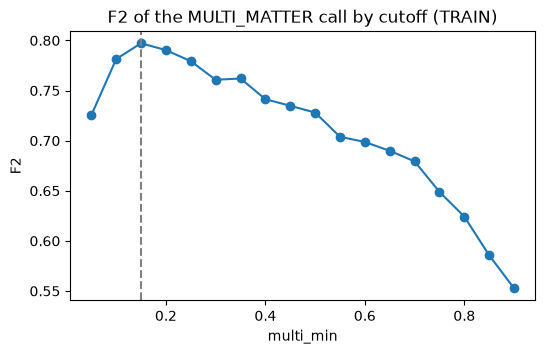

multi_min = 0.15


In [11]:
multi_score = pd.Series({t: fbeta_score(is_multi, action_cv["multi"] >= t, beta=MULTI_BETA) for t in MULTI_GRID})
multi_min = float(multi_score.idxmax())
ax = multi_score.plot(marker="o", figsize=(6, 3.5), title=f"F{MULTI_BETA} of the MULTI_MATTER call by cutoff (TRAIN)")
ax.axvline(multi_min, color="gray", linestyle="--")
ax.set(xlabel="multi_min", ylabel=f"F{MULTI_BETA}")
plt.show()
print(f"multi_min = {multi_min}")

In [12]:
same_for_all = {"multi_min": multi_min, "correct_typed_cmid": CORRECT_TYPED_CMID}
two_sweep, two_scored = {}, {}
for settings in itertools.product(*ACTION_GRID.values()):
    cfg = dict(zip(ACTION_GRID, settings)) | same_for_all
    two_scored[settings] = score(route_actions(entries_train, action_cv, cfg), answers)
    two_sweep[settings] = summarize(two_scored[settings])
two_sweep = pd.DataFrame(two_sweep).T.rename_axis(list(ACTION_GRID))

rules_precision = baseline.query("method == 'rules' and split == 'TRAIN' and entry_set == 'all'")["decided_precision"].iloc[0]


def pick(target):
    best = pick_robust(two_scored, target, ROBUST_SHARE, STABILITY_RESAMPLES, SEED)
    return {k: float(v) for k, v in zip(ACTION_GRID, best)} | same_for_all


strict, default, balanced = pick(PRECISION_TARGET), pick(DEFAULT_TARGET), pick(rules_precision)
print("Strict:", strict, "| Default:", default, "| Balanced:", balanced)

pd.DataFrame({"one step": one_sweep.loc[tuple(one_step.values())],
              "two steps, strict": two_sweep.loc[(strict["auto_min"], strict["no_match_min"])],
              "two steps, default": two_sweep.loc[(default["auto_min"], default["no_match_min"])],
              "two steps, balanced": two_sweep.loc[(balanced["auto_min"], balanced["no_match_min"])]}).T[
    ["decided_precision", "straight_through", "review_share", "multi_share", "multi_flag_right", "multi_caught", "no_match_precision"]].round(3)

Strict: {'auto_min': 0.97, 'no_match_min': 0.9, 'multi_min': 0.15, 'correct_typed_cmid': True} | Default: {'auto_min': 0.9, 'no_match_min': 0.9, 'multi_min': 0.15, 'correct_typed_cmid': True} | Balanced: {'auto_min': 0.5, 'no_match_min': 0.3, 'multi_min': 0.15, 'correct_typed_cmid': True}


,decided_precision,straight_through,review_share,multi_share,multi_flag_right,multi_caught,no_match_precision
one step,0.960,0.160,0.744,0.001,0.500,0.006,0.894
"two steps, strict",0.988,0.581,0.272,0.081,0.650,0.845,0.980
"two steps, default",0.978,0.717,0.153,0.081,0.650,0.845,0.980
"two steps, balanced",0.930,0.880,0.025,0.080,0.652,0.839,0.822


- **`multi_min` lands at 0.15.** Weighting misses more than false alarms pushes the cutoff low: on TRAIN, 85% of multi-matter entries get the call, and 65% of calls are right. Precision and the straight-through rate don't depend on this cutoff, since every `MULTI_MATTER` call goes to a person anyway.
- **Strict** reaches 98.8% decided precision with 58% of entries decided with no person.
- **Default** reaches 97.8% and decides 72% with no person, sending 15% to review instead of 27%.
- **Balanced** gives up more (93.0%) to decide 88% with no person and send only 3% to review.
- **The margin shows:** strict and default land almost a point above their targets on TRAIN, which leaves room for a slightly different set of entries.
- Strict and default share the new-client cutoff (`no_match_min` 0.9), and 98% of those calls are right.

### How stable are the cutoffs?

TRAIN is resampled by timekeeper (whole timekeepers drawn with replacement, since one person's entries are alike), and the best setting is picked again each time with the plain rule, no margin (`cutoff_stability`). The table shows how often each setting wins. Nothing is refit, so this measures how much the choice depends on which entries are in TRAIN.

In [13]:
stability = pd.DataFrame({name: cutoff_stability(two_scored, target, STABILITY_RESAMPLES, SEED)
                          for name, target in [("strict", PRECISION_TARGET), ("default", DEFAULT_TARGET)]}).fillna(0)
stability.index = [f"auto_min {a}, no_match_min {n}" for a, n in stability.index]
stability.sort_values("default", ascending=False).round(2)

,strict,default
"auto_min 0.85, no_match_min 0.9",0.10,0.26
"auto_min 0.85, no_match_min 0.5",0.00,0.20
"auto_min 0.85, no_match_min 0.7",0.03,0.20
"auto_min 0.8, no_match_min 0.7",0.00,0.10
"auto_min 0.9, no_match_min 0.9",0.22,0.08
"auto_min 0.8, no_match_min 0.9",0.00,0.06
"auto_min 0.8, no_match_min 0.5",0.00,0.02
"auto_min 0.93, no_match_min 0.9",0.18,0.02
"auto_min 0.7, no_match_min 0.7",0.00,0.02
"auto_min 0.85, no_match_min 0.95",0.02,0.01


- **The exact cutoffs aren't stable.** The most common plain default pick wins only about 1 in 4 resamples, and strict's choices are spread from 0.85 to 0.97.
- **The range is narrower:** default's `auto_min` lands between 0.8 and 0.9 in about 19 of 20 resamples.
- **The margin picks the cautious end:** default's chosen `auto_min` is 0.9, at the top of the plain pick's range, and strict's is 0.97.
- **`no_match_min` moves the most** (0.5 to 0.95), so how many entries are called new clients is the least settled part of the setup.
- In practice, the target (97% or 98%) is the decision that matters. The exact cutoff it lands on should be re-picked whenever the model is refit.

### Precision vs. straight-through rate

Each line moves `auto_min` with the other cutoffs at their strict values. Up and to the right is better: more entries decided with no person, at higher precision.

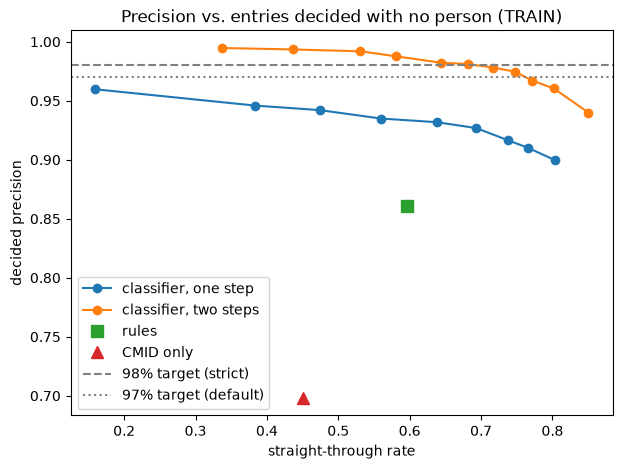

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, sweep, cfg, fixed in [("one step", one_sweep, one_step, ["multi_min", "no_match_max"]),
                                ("two steps", two_sweep, strict, ["no_match_min"])]:
    curve = sweep.xs(tuple(cfg[k] for k in fixed), level=fixed)
    ax.plot(curve["straight_through"], curve["decided_precision"], marker="o", label=f"classifier, {name}")
for method, marker in [("rules", "s"), ("CMID only", "^")]:
    row = baseline.query("method == @method and split == 'TRAIN' and entry_set == 'all'").iloc[0]
    ax.plot(row["straight_through"], row["decided_precision"], marker=marker, markersize=9, linestyle="", label=method)
ax.axhline(PRECISION_TARGET, color="gray", linestyle="--", label="98% target (strict)")
ax.axhline(DEFAULT_TARGET, color="gray", linestyle=":", label="97% target (default)")
ax.set(title="Precision vs. entries decided with no person (TRAIN)", xlabel="straight-through rate", ylabel="decided precision")
ax.legend()
plt.show()

- **The two-step line sits above the one-step line everywhere** and crosses both targets, which one step never reaches.
- At about half of entries decided with no person, two steps is about 5 points more precise (about 99% vs. 94%).
- Two steps stays at 98% or above up to about 68% of entries decided with no person, and at 97% or above up to about 75%.
- The rules and CMID only sit well below both classifier lines.

## 8. The default classifier on TRAIN

Rows are what the answer key expects and columns are what the classifier decided.

In [15]:
scored_train = score(route_actions(entries_train, action_cv, default), answers)
pd.crosstab(scored_train["key_expected_action"], scored_train["action"]).reindex(index=ACTIONS, columns=ACTIONS, fill_value=0)

action,AUTO_MATCH,FLAG_MISMATCH,NEEDS_REVIEW,MULTI_MATTER,NO_MATCH
key_expected_action,,,,,
AUTO_MATCH,1715,86,258,60,1
FLAG_MISMATCH,82,51,22,13,0
NEEDS_REVIEW,93,0,70,2,1
MULTI_MATTER,17,0,10,147,0
NO_MATCH,4,0,70,4,96


In [16]:
wrong = scored_train[scored_train["outcome"] == "Accepted, wrong"]
wrong["key_entry_category"].value_counts().rename("wrong auto-accepts").to_frame()

,wrong auto-accepts
key_entry_category,
MULTI_NAMED,16
WRONG_CMID_TEXT,6
NO_MATCH,4
WRONG_CMID_SILENT,4
AMBIGUOUS,4
INCOMPLETE,4
CLEAN,2
MULTI_UNNAMED,1
MESSY,1


- **Most multi-matter entries are caught:** 147 of 174 get the call. Of the rest, 17 are auto-matched to one matter and 10 go to review.
- **The price is false alarms:** 79 one-matter entries also get the call. Each costs a reviewer a few seconds to clear.
- **Wrong auto-accepts stay low:** 42 out of about 1,900 auto-accepts. 17 are multi-matter entries accepted as one matter, 10 are wrong CMIDs, and the rest are spread across vague entries and new clients.
- **Review is about 1 in 7 entries,** and about 3 in 5 reviewed entries should have been auto-matched, so most reviews are a quick confirmation.
- **New clients mostly go to review** (70 of 174) or get the call (96), and almost never get auto-matched (4).

## 9. Which clues matter? (step 1)

Each group of clues is dropped in turn, the step-1 model is retrained with the same settings, and the change in cross-validated top-1 accuracy is recorded. A big drop means the model leans on that group. This retrains the model about 40 times, so it takes a few minutes.

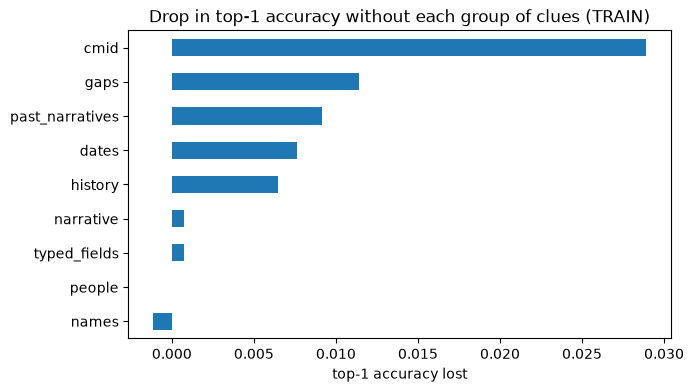

In [17]:
full_top_1 = model_scores.loc[chosen_model, "top_1"]

drop = {}
for group, cols in feature_groups.items():
    kept = [c for c in FEATURES if c not in cols]
    p = cross_val_predict(clone(best_model), X_train[kept], y_train, cv=cv, method="predict_proba")[:, 1]
    drop[group] = full_top_1 - top_k_accuracy(train_pairs, p, k=1)

ax = pd.Series(drop).sort_values().plot.barh(figsize=(7, 4), title="Drop in top-1 accuracy without each group of clues (TRAIN)")
ax.set_xlabel("top-1 accuracy lost")
plt.show()

- **The CMID clues matter most** (about 3 points of top-1), then the gaps to the best candidate, past narratives, dates, and timekeeper history (about 0.6 to 1 point each).
- **The narrative, typed-field flags, people, and typed names barely move top-1 on their own** (0.1 points or less), likely because other clues carry the same information.
- This only measures step 1. Notebook 07 drops the same groups and runs the full system, which shows what each group adds to the decisions.

## 10. Check on VAL (once)

Both models are refit on all of TRAIN, and VAL goes through both steps with the cutoffs from sections 6 and 7. Nothing changes after this.

The range is a 95% bootstrap interval for decided precision. With about 600 entries, differences of 2 to 3 points can be noise.

In [18]:
val_probs = best_model.predict_proba(val_pairs[FEATURES])[:, 1]
entries_val = entry_features(val_pairs, val_probs, CLIENT_COL, MATTER_COL, feature_config["phrase_min"])
entries_val["multi_text_score"] = text_model.predict_proba(entries_val["entry_id"].map(narratives))[:, 1]
action_val = pd.DataFrame(action_model.predict_proba(entries_val[ACTION_FEATURES]), columns=action_model.classes_)

runs = {("classifier, one step", "TRAIN"): scored_one,
        ("classifier, one step", "VAL"): score(route(top_candidates(val_pairs, val_probs), one_step), answers),
        ("classifier (strict)", "TRAIN"): score(route_actions(entries_train, action_cv, strict), answers),
        ("classifier (strict)", "VAL"): score(route_actions(entries_val, action_val, strict), answers),
        ("classifier (default)", "TRAIN"): scored_train,
        ("classifier (default)", "VAL"): score(route_actions(entries_val, action_val, default), answers),
        ("classifier (balanced)", "TRAIN"): score(route_actions(entries_train, action_cv, balanced), answers),
        ("classifier (balanced)", "VAL"): score(route_actions(entries_val, action_val, balanced), answers)}

rows = {}
for (method, split), scored in runs.items():
    rows[(method, split, "all")] = summarize(scored)
    rows[(method, split, "non-trivial")] = summarize(scored[scored["key_trivial"] == "N"])
new_rows = pd.DataFrame(rows).T.rename_axis(["method", "split", "entry_set"]).reset_index()
comparison = pd.concat([baseline[~baseline["method"].str.startswith("classifier")], new_rows], ignore_index=True)

val_runs = {"CMID only": score(run_rules(val_pairs, rules_config["rules"], cmid_only), answers),
            "rules": score(run_rules(val_pairs, rules_config["rules"]), answers)}
val_runs |= {method: scored for (method, split), scored in runs.items() if split == "VAL"}

val_table = pd.DataFrame({name: summarize(scored) for name, scored in val_runs.items()}).T
val_table[["ci_low", "ci_high"]] = [precision_ci(scored) for scored in val_runs.values()]
val_table[["decided_precision", "ci_low", "ci_high", "straight_through", "review_share", "silent_errors", "silent_by_design",
           "multi_share", "multi_flag_right", "multi_caught", "no_match_precision", "shortlist_hit"]].round(3)

,decided_precision,ci_low,ci_high,straight_through,review_share,silent_errors,silent_by_design,multi_share,multi_flag_right,multi_caught,no_match_precision,shortlist_hit
CMID only,0.687,0.632,0.747,0.431,0.569,81.0,32.0,0.000,NaN,0.000,NaN,0.693
rules,0.872,0.831,0.907,0.572,0.324,36.0,17.0,0.022,0.692,0.243,0.771,0.605
"classifier, one step",0.971,0.939,1.000,0.173,0.734,1.0,0.0,0.002,0.000,0.000,0.875,0.937
classifier (strict),0.991,0.981,1.000,0.577,0.290,2.0,2.0,0.077,0.652,0.811,0.947,0.885
classifier (default),0.977,0.964,0.989,0.735,0.151,9.0,4.0,0.077,0.652,0.811,0.947,0.791
classifier (balanced),0.936,0.918,0.952,0.887,0.027,29.0,10.0,0.075,0.667,0.811,0.848,0.750


In [19]:
main = {name: scored for name, scored in val_runs.items() if name != "CMID only"}
accuracy = pd.DataFrame({name: {"matter_accuracy": scored["matter_right"].mean(),
                                "non_trivial": scored.loc[scored["key_trivial"] == "N", "matter_right"].mean(),
                                "action_accuracy": scored["action_right"].mean(),
                                "silent_errors": (scored["outcome"] == "Accepted, wrong").sum()}
                         for name, scored in main.items()}).T
val_table[["decided_precision", "straight_through"]].join(accuracy, how="inner").round(3)

,decided_precision,straight_through,matter_accuracy,non_trivial,action_accuracy,silent_errors
rules,0.872,0.572,0.654,0.561,0.637,36.0
"classifier, one step",0.971,0.173,0.864,0.821,0.278,1.0
classifier (strict),0.991,0.577,0.870,0.832,0.629,2.0
classifier (default),0.977,0.735,0.870,0.832,0.727,9.0
classifier (balanced),0.936,0.887,0.884,0.850,0.804,29.0


In [20]:
from sklearn.metrics import classification_report

for name in ["classifier (strict)", "classifier (default)", "classifier (balanced)"]:
    scored = val_runs[name]
    hard = scored["key_trivial"] == "N"
    print(f"# {name}\n== VAL ==")
    print(f"matter accuracy {scored['matter_right'].mean():.3f} | non-trivial {scored.loc[hard, 'matter_right'].mean():.3f} | "
          f"silent errors {(scored['outcome'] == 'Accepted, wrong').sum()}")
    print(f"action accuracy {scored['action_right'].mean():.3f}")
    print(classification_report(scored["key_expected_action"], scored["action"], digits=3, zero_division=0))

# classifier (strict)
== VAL ==
matter accuracy 0.870 | non-trivial 0.832 | silent errors 2
action accuracy 0.629
               precision    recall  f1-score   support

   AUTO_MATCH      0.902     0.653     0.758       453
FLAG_MISMATCH      0.500     0.472     0.486        36
 MULTI_MATTER      0.652     0.811     0.723        37
 NEEDS_REVIEW      0.098     0.447     0.160        38
     NO_MATCH      0.947     0.486     0.643        37

     accuracy                          0.629       601
    macro avg      0.620     0.574     0.554       601
 weighted avg      0.815     0.629     0.695       601

# classifier (default)
== VAL ==
matter accuracy 0.870 | non-trivial 0.832 | silent errors 9
action accuracy 0.727
               precision    recall  f1-score   support

   AUTO_MATCH      0.877     0.819     0.847       453
FLAG_MISMATCH      0.455     0.278     0.345        36
 MULTI_MATTER      0.652     0.811     0.723        37
 NEEDS_REVIEW      0.088     0.211     0.124        

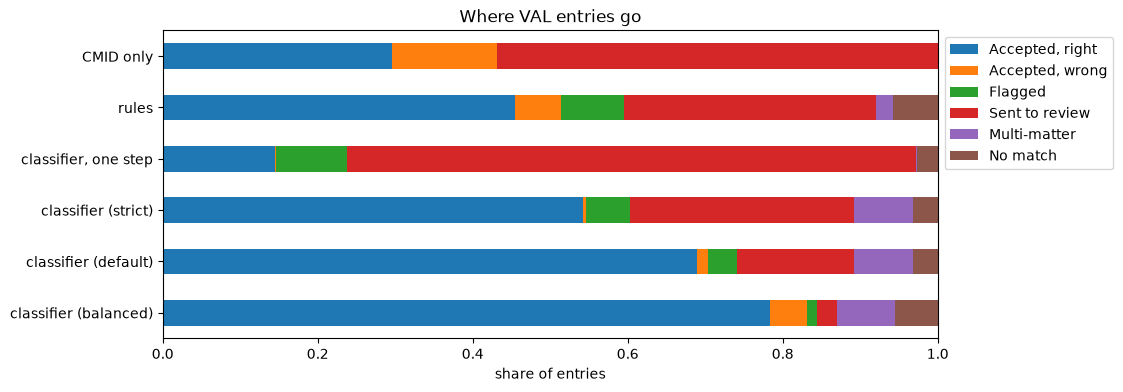

In [21]:
shares = pd.DataFrame({name: scored["outcome"].value_counts(normalize=True) for name, scored in val_runs.items()}).T[OUTCOMES].fillna(0)
ax = shares.plot.barh(stacked=True, figsize=(10, 4), xlim=(0, 1), title="Where VAL entries go")
ax.set_xlabel("share of entries")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.invert_yaxis()
plt.show()

| VAL | Decided precision | No person | Review | Silent errors |
|---|---|---|---|---|
| Rules | 87.2% | 57% | 32% | 36 |
| One step | 97.1% | 17% | 73% | 1 |
| Strict | 99.1% | 58% | 29% | 2 |
| **Default** | **97.7%** | **74%** | **15%** | **9** |
| Balanced | 93.6% | 89% | 3% | 29 |

- **Default vs. rules:** the precision ranges don't overlap (96.4 to 98.9% vs. 83.1 to 90.7%), so the gain is real, not noise.
- **Default vs. strict:** strict makes 7 fewer silent errors but sends twice as much to review.
- **One step is precise but barely automates,** since it can't recognize multi-matter entries.
- **`MULTI_MATTER`:** 81% of multi-matter entries are caught and 65% of calls are right (rules: 24% caught).
- **New clients:** 95% of `NO_MATCH` calls are right, but only about half of new clients get the call. The rest go to review.
- **Reviews are quick checks:** the right matter is in the top 3 for 79% of reviewed entries (rules: 61%).
- **No overfitting:** VAL matches TRAIN (97.7% vs. 97.8%, 74% vs. 72% decided with no person).

## 11. Reasons for each decision

A reviewer needs to know why the tool chose what it chose, but won't read a paragraph per entry. So `explain` gives each decision two reasons:
- **`reason_short`:** a few words for the review list ("Typed CMID matches", "Client clear, matter unclear")
- **`reason_full`:** the decision, a confidence level (high 0.9+, medium 0.5+, low), the top pick's strongest clues, and the shortlist. A multi-matter call also suggests which piece of work goes to which matter and why the second matter was picked.

**The model picks the clues.** LightGBM can split each decision's score into how much every input pushed it (`pred_contrib`). `explain` adds those up per clue (`clue_weights`) and only cites clues that are there for that entry *and* pushed toward the pick, strongest first. So a reason never cites a clue the entry doesn't have, and two similar entries can get different reasons depending on what drove each one.

In [22]:
parts["other_work_score"] = text_model.predict_proba(parts["part_norm"])[:, 1]
inputs = {"TRAIN": (entries_train, train_pairs), "VAL": (entries_val, val_pairs)}
for method, split in runs:
    if method == "classifier, one step":
        continue
    entries, table = inputs[split]
    runs[(method, split)] = explain(runs[(method, split)], entries, table, CLIENT_COL, MATTER_COL, feature_config["phrase_min"], parts,
                                    best_model, FEATURES)

chosen_val = runs[("classifier (default)", "VAL")]
for _, row in chosen_val.groupby("action").head(2).sort_values("action").iterrows():
    print(f"{row['action']:<14} {row['reason_short']}\n{'':<14} {row['reason_full']}\n")

AUTO_MATCH     You've billed this matter
               Auto-match to 6103.004 (Meridian Therapeutics - 2026 Annual Meeting), high confidence: the timekeeper billed 125.4 hours to it recently; the typed client matches Meridian Therapeutics; the narrative reads like past entries on this matter.

AUTO_MATCH     Typed CMID matches
               Auto-match to 6103.004 (Meridian Therapeutics - 2026 Annual Meeting), high confidence: the typed CMID is this matter; the timekeeper billed 125.4 hours to it recently; the narrative reads like past entries on this matter.

FLAG_MISMATCH  Typed CMID doesn't fit narrative
               Flag: Typed CMID doesn't fit narrative. Suggested 6103.004 (Meridian Therapeutics - 2026 Annual Meeting), low confidence: the typed client matches Meridian Therapeutics; the timekeeper billed 5.5 hours to it recently.

FLAG_MISMATCH  Typed CMID doesn't fit narrative
               Flag: Typed CMID doesn't fit narrative. Suggested 8340.001 (Pelican Row Holdings - Acqu

In [23]:
chosen_val.groupby("action")["reason_short"].value_counts().rename("VAL entries").to_frame()

VAL entries
action        reason_short                                 
AUTO_MATCH    You've billed this matter                 197
              Typed CMID matches                         81
              Typed client matches                       67
              Typed CMID corrected                       33
              Narrative names the matter                 23
              Reads like past entries                    20
              Typed matter matches                        2
FLAG_MISMATCH Typed CMID doesn't fit narrative           22
MULTI_MATTER  May cover two matters                      33
              Mentions other work                        12
              Names two matters                           1
NEEDS_REVIEW  Not sure enough to accept                  44
              No clear match                             25
              Client clear, matter unclear               15
              Close call between matters                  7
NO_MATCH      Likely a new client or matter              19

- **Every decision says why in a few words.** Auto-matches most often cite the timekeeper's own billing on the matter (197 of 423), then the typed CMID (81) and the typed client (67). The 33 that correct the typed CMID say so, and flags say the typed CMID doesn't fit the narrative.
- **Reasons follow what drove each decision,** so two auto-matches to the same matter can lead with different clues (the first two examples).
- **Review reasons tell the reviewer where to look:** "Not sure enough to accept" is the most common (44 of 91), then no clear match (25), client clear but matter unclear (15), and a close call between matters (7).
- **Multi-matter calls say why:** most may cover two matters (33), and the rest mention other work (12) or name two matters (1). Split suggestions put the part that seems to be other work on its own, so the timekeeper only has to confirm the second matter and divide the hours.

### The same steps in `src/train.py`

`src/train.py` has this notebook's training steps as functions (`fit_pair_model`, `fit_action_model`, `pick_cutoffs`), so the system can be retrained on a firm's own history without the notebook.
- A firm sets **targets** (`SETTINGS`), not raw cutoffs.
- `pick_cutoffs` re-picks cutoffs for a new target in seconds, without refitting the models.

The check runs them with this notebook's settings and makes sure they give the same probabilities and cutoffs.

In [24]:
check_settings = SETTINGS | {"robust_share": ROBUST_SHARE, "resamples": STABILITY_RESAMPLES, "multi_beta": MULTI_BETA,
                              "correct_typed_cmid": CORRECT_TYPED_CMID, "seed": SEED, "phrase_min": feature_config["phrase_min"]}
one_point = lambda params: {k: [v] for k, v in params.items()}

check_model, check_probs, _ = fit_pair_model(train_pairs, FEATURES, one_point(searches[chosen_model].best_params_), SEED)
check_step2 = fit_action_model(train_pairs, check_probs, answers, CLIENT_COL, MATTER_COL, one_point(text_search.best_params_),
                               one_point(action_search.best_params_), check_settings)
check_routing = pick_cutoffs(check_step2["entries"], check_step2["action_cv"], answers,
                             {"strict": PRECISION_TARGET, "default": DEFAULT_TARGET, "balanced": rules_precision},
                             check_settings, ACTION_GRID, list(MULTI_GRID))

assert np.allclose(check_probs, cv_probs[chosen_model])
assert np.allclose(check_step2["action_cv"].to_numpy(), action_cv.to_numpy())
assert check_routing == {"strict": strict, "default": default, "balanced": balanced}, check_routing
print("src/train.py matches this notebook: same probabilities, same action probabilities, same cutoffs")

src/train.py matches this notebook: same probabilities, same action probabilities, same cutoffs


## 12. Save

- `04_decisions.csv`: one row per TRAIN and VAL entry for each classifier version (`method`), with both reasons, top probabilities, and shortlist. Same columns as `03_decisions.csv` where they overlap.
- `03_comparison.csv`: now also has the classifier's rows
- `04_config.json`: the chosen model, its settings, and all cutoffs
- `04_model.joblib`: the three trained models (pairs, narrative text, action)

In [25]:
decisions = pd.concat([scored.assign(method=method) for (method, split), scored in runs.items()], ignore_index=True)
decisions.to_csv(RESULTS_DIR / "04_decisions.csv", index=False)
comparison.to_csv(RESULTS_DIR / "03_comparison.csv", index=False)
joblib.dump({"pair_model": best_model, "text_model": text_model, "action_model": action_model}, RESULTS_DIR / "04_model.joblib")

config = {"model": chosen_model, "model_params": searches[chosen_model].best_params_, "features": FEATURES,
          "action_features": ACTION_FEATURES, "text_model_params": text_search.best_params_,
          "action_model_params": action_search.best_params_, "routing": {"one_step": one_step, "strict": strict, "default": default, "balanced": balanced},
          "multi_beta": MULTI_BETA, "precision_target": PRECISION_TARGET, "default_target": DEFAULT_TARGET,
          "robust_share": ROBUST_SHARE}
(RESULTS_DIR / "04_config.json").write_text(json.dumps(config, indent=2, default=str))
print("Saved:", ", ".join(p.name for p in sorted(RESULTS_DIR.glob("04_*"))), "+ 03_comparison.csv")

Saved: 04_config.json, 04_decisions.csv, 04_model.joblib + 03_comparison.csv


## 13. Findings

### Results
- **Step 1:** gradient boosting (LightGBM) ranks the right matter first for 92% of TRAIN entries and in the top 3 for 98%, with probabilities close to calibrated.
- **One step tops out at 96% on TRAIN** while deciding only 16% of entries, because a cutoff on one candidate's probability can't tell when an entry covers two matters.
- **Two steps reach both targets on TRAIN with a margin:** strict 98.8% and default 97.8%.
- **On VAL, default gets 97.7%** (range 96.4 to 98.9%) while deciding 74% of entries with no person, vs. 57% for the rules, and cuts silent errors from 36 to 9.
- **The `MULTI_MATTER` call catches 81% of multi-matter entries on VAL.**
- **Every decision comes with a short and a full reason** that cite the clues that pushed that decision.

### Tradeoffs and decisions
- **Default over strict:** about 14 more points of automation on TRAIN for about one point of precision. On VAL that costs 7 more silent errors (9 vs. 2).
- **Misses vs. false alarms on multi-matter entries:** F2 accepts about 1 false alarm in 3 calls to catch more of them, since a miss costs money and a false alarm costs seconds.
- **A margin on the cutoffs:** picking the cautious end of the stable range gives up a little automation on TRAIN so VAL stays above the target.
- **Typed-CMID corrections:** confident corrections save review, and the reason always says the CMID was changed. A firm can turn this off.
- **Realistic clues only:** key terms from matter names, and past narratives and people from billing history, with no curated key-term list.

### Limitations
- The data is synthetic, and the models learn its patterns closely. The text model especially learns the phrase bank's wording for other work, so a firm's entries would likely score lower until the models are retrained on its history.
- About 1 in 5 multi-matter entries isn't caught. Those go to review or are auto-matched to one matter, where the second can be missed.
- `no_match_min` is the least stable setting, so how many entries get `NO_MATCH` can change when the model is refit.
- Reasons come from the model's contributions, which say what moved the score, not why the entry is right. Two clues carrying the same information can split the credit.
- Matter type and dates are assumed to be in the firm's matter list.

### Next steps
- Check the reasons and split suggestions with billing staff: are they short and clear enough to act on?
- Run the frozen system once on TEST and the holdout file (notebook 06).
- `src/train.py` reproduces these models and cutoffs, so a firm can retrain on its own history with targets instead of raw cutoffs.